# Wettervergleich Berlin 2025: Open-Meteo und DWD

Dieses Notebook vergleicht tägliche Wetterwerte des Jahres 2025 für Berlin-Tempelhof. Open-Meteo liefert Archivdaten für die Koordinaten der DWD-Station; als Referenz dienen die Stationsmessungen des Deutschen Wetterdienstes (DWD), Stations-ID `00433`.

Datenquellen: [DWD Climate Data Center](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/) und [Open-Meteo Archive API](https://archive-api.open-meteo.com/v1/archive). Für beide Abrufe ist eine Internetverbindung erforderlich.

Die Quellen messen nicht exakt dasselbe: DWD ist eine Stationsmessung, Open-Meteo ein Wert am Koordinatenpunkt. Auch Messverfahren und Tagesgrenzen können abweichen, besonders beim Niederschlag; Differenzen sind daher nicht automatisch Datenfehler.

## 1. Bibliotheken und Vergleichszeitraum

Benötigt werden `pandas`, `matplotlib` und `requests`. Falls sie fehlen, installiere sie mit `%pip install pandas matplotlib requests`. Die DWD-Tageswerte stammen aus dem Climate Data Center (CDC); Open-Meteo stellt die Vergleichswerte bereit.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import requests
from html.parser import HTMLParser
from io import BytesIO
from requests.adapters import HTTPAdapter
from urllib.parse import urljoin
from urllib3.util.retry import Retry
from zipfile import ZipFile

retry = Retry(
    total=4,
    connect=4,
    read=2,
    backoff_factor=1,
    status_forcelist=(429, 500, 502, 503, 504),
    allowed_methods=frozenset({"GET"}),
)
session = requests.Session()
session.mount("https://", HTTPAdapter(max_retries=retry))

jahr = 2025
start_date = f"{jahr}-01-01"
end_date = f"{jahr}-12-31"
berlin = {"latitude": 52.4675, "longitude": 13.4020}
dwd_station_id = "00433"

## 2. Open-Meteo-Archivdaten laden

Temperaturen und Niederschlag werden täglich abgerufen. Für den Wind wird der Mittelwert der stündlichen 10-m-Windgeschwindigkeit pro Berliner Kalendertag gebildet, damit er mit dem DWD-Tagesmittel vergleichbar ist.

In [2]:
open_meteo_url = "https://archive-api.open-meteo.com/v1/archive"
open_meteo_parameter = {
    **berlin,
    "start_date": start_date,
    "end_date": end_date,
    "daily": "temperature_2m_max,temperature_2m_min,precipitation_sum",
    "hourly": "wind_speed_10m",
    "timezone": "Europe/Berlin",
    "wind_speed_unit": "kmh",
}

open_meteo_response = session.get(open_meteo_url, params=open_meteo_parameter, timeout=60)
open_meteo_response.raise_for_status()
open_meteo_payload = open_meteo_response.json()
open_meteo_daily = open_meteo_payload["daily"]
open_meteo_hourly = open_meteo_payload["hourly"]

wind_hourly = pd.DataFrame({
    "datum": pd.to_datetime(open_meteo_hourly["time"]).date,
    "wind_kmh": open_meteo_hourly["wind_speed_10m"],
})
wind_daily = wind_hourly.groupby("datum")["wind_kmh"].mean()

open_meteo = pd.DataFrame({
    "datum": pd.to_datetime(open_meteo_daily["time"]),
    "temperatur_max_c_openmeteo": open_meteo_daily["temperature_2m_max"],
    "temperatur_min_c_openmeteo": open_meteo_daily["temperature_2m_min"],
    "niederschlag_mm_openmeteo": open_meteo_daily["precipitation_sum"],
})
open_meteo["wind_mittel_kmh_openmeteo"] = open_meteo["datum"].dt.date.map(wind_daily)

print(f"Open-Meteo: {len(open_meteo)} Tageswerte für {jahr}")
display(open_meteo.head())

Open-Meteo: 365 Tageswerte für 2025


,datum,temperatur_max_c_openmeteo,temperatur_min_c_openmeteo,niederschlag_mm_openmeteo,wind_mittel_kmh_openmeteo
0,2025-01-01,7.0,0.5,0.1,22.883333
1,2025-01-02,6.9,1.0,3.9,17.316667
2,2025-01-03,2.6,-1.3,4.6,19.720833
3,2025-01-04,0.9,-2.3,0.0,12.104167
4,2025-01-05,1.8,-2.4,9.4,11.587500


## 3. DWD-Tageswerte für Berlin-Tempelhof laden

Der DWD stellt Stationsdaten als ZIP-Dateien im Climate Data Center bereit. Das Notebook sucht die Dateien für Station `00433` in den Verzeichnissen `historical` und `recent`, liest sie ein und behält nur Messungen aus 2025.

In [3]:
class ZipIndexParser(HTMLParser):
    def __init__(self):
        super().__init__()
        self.links = []

    def handle_starttag(self, tag, attrs):
        if tag == "a":
            href = dict(attrs).get("href", "")
            if href.endswith(".zip"):
                self.links.append(href)


def station_archive_urls(directory_url):
    response = session.get(directory_url, timeout=60)
    response.raise_for_status()
    parser = ZipIndexParser()
    parser.feed(response.text)
    prefix = f"tageswerte_KL_{dwd_station_id}_"
    return sorted(
        urljoin(directory_url, href)
        for href in parser.links
        if href.rsplit("/", 1)[-1].startswith(prefix)
    )


dwd_base_url = (
    "https://opendata.dwd.de/climate_environment/CDC/"
    "observations_germany/climate/daily/kl/"
)
historical_urls = station_archive_urls(dwd_base_url + "historical/")
recent_urls = station_archive_urls(dwd_base_url + "recent/")
dwd_archive_urls = historical_urls[-1:] + recent_urls[-1:]

if not dwd_archive_urls:
    raise FileNotFoundError(f"Keine DWD-Tagesarchive für Station {dwd_station_id} gefunden.")

print("DWD-Archive:")
for archive_url in dwd_archive_urls:
    print(archive_url.rsplit("/", 1)[-1])

dwd_raw_frames = []
for archive_url in dwd_archive_urls:
    response = session.get(archive_url, timeout=120)
    response.raise_for_status()
    with ZipFile(BytesIO(response.content)) as archive:
        text_files = [
            name for name in archive.namelist()
            if name.startswith("produkt_klima_tag_") and name.endswith(".txt")
        ]
        if not text_files:
            raise FileNotFoundError(f"Keine DWD-Produktdatei in {archive_url} gefunden.")
        with archive.open(text_files[0]) as data_file:
            dwd_frame = pd.read_csv(
                data_file,
                sep=";",
                na_values=["-999", "-999.0"],
                dtype={"MESS_DATUM": "string"},
                low_memory=False,
            )
        dwd_frame.columns = dwd_frame.columns.str.strip()
        dwd_raw_frames.append(dwd_frame)

dwd_rohdaten = pd.concat(dwd_raw_frames, ignore_index=True)
dwd_rohdaten["datum"] = pd.to_datetime(
    dwd_rohdaten["MESS_DATUM"], format="%Y%m%d", errors="coerce"
)
dwd_2025_roh = dwd_rohdaten.loc[dwd_rohdaten["datum"].dt.year == jahr].copy()

if dwd_2025_roh.empty:
    raise ValueError(f"Die DWD-Archive enthalten keine Messwerte für {jahr}.")

dwd = pd.DataFrame({
    "datum": dwd_2025_roh["datum"],
    "temperatur_max_c_dwd": pd.to_numeric(dwd_2025_roh["TXK"], errors="coerce"),
    "temperatur_min_c_dwd": pd.to_numeric(dwd_2025_roh["TNK"], errors="coerce"),
    "niederschlag_mm_dwd": pd.to_numeric(dwd_2025_roh["RSK"], errors="coerce"),
    "wind_mittel_kmh_dwd": pd.to_numeric(dwd_2025_roh["FM"], errors="coerce") * 3.6,
}).drop_duplicates("datum", keep="last").sort_values("datum")

display(dwd.head())
print(f"DWD: {len(dwd)} Tageswerte für {jahr}")

DWD-Archive:
tageswerte_KL_00433_19480101_20251231_hist.zip
tageswerte_KL_00433_akt.zip


,datum,temperatur_max_c_dwd,temperatur_min_c_dwd,niederschlag_mm_dwd,wind_mittel_kmh_dwd
28125,2025-01-01,8.5,2.0,0.8,25.56
28126,2025-01-02,8.4,2.0,0.2,19.80
28127,2025-01-03,3.8,-1.0,0.4,23.04
28128,2025-01-04,0.6,-0.8,0.0,14.40
28129,2025-01-05,1.2,-2.6,10.9,12.96


DWD: 365 Tageswerte für 2025


## 4. Messwerte taggenau zusammenführen und vergleichen

Verglichen werden nur Tage, für die beide Quellen Messwerte haben. Die mittlere Abweichung zeigt die Richtung des Unterschieds; der mittlere absolute Fehler (MAE) beschreibt dessen typische Größe.

In [4]:
vergleich = open_meteo.merge(dwd, on="datum", how="inner", validate="one_to_one")

messgroessen = [
    ("Tageshöchsttemperatur (°C)", "temperatur_max_c_openmeteo", "temperatur_max_c_dwd"),
    ("Tagestiefsttemperatur (°C)", "temperatur_min_c_openmeteo", "temperatur_min_c_dwd"),
    ("Niederschlag (mm/Tag)", "niederschlag_mm_openmeteo", "niederschlag_mm_dwd"),
    ("Mittlerer Wind (km/h)", "wind_mittel_kmh_openmeteo", "wind_mittel_kmh_dwd"),
]

kennzahlen = []
for bezeichnung, open_meteo_spalte, dwd_spalte in messgroessen:
    paare = vergleich[[open_meteo_spalte, dwd_spalte]].dropna()
    abweichung = paare[open_meteo_spalte] - paare[dwd_spalte]
    kennzahlen.append({
        "Messgröße": bezeichnung,
        "Vergleichstage": len(paare),
        "Mittlere Abweichung": abweichung.mean(),
        "MAE": abweichung.abs().mean(),
    })

display(pd.DataFrame(kennzahlen).set_index("Messgröße").round(2))
print(f"Gemeinsame Tage: {len(vergleich)} von maximal 365")

,Vergleichstage,Mittlere Abweichung,MAE
Messgröße,,,
Tageshöchsttemperatur (°C),365,-0.78,1.02
Tagestiefsttemperatur (°C),365,0.38,0.88
Niederschlag (mm/Tag),365,0.38,1.07
Mittlerer Wind (km/h),365,-1.84,2.23


Gemeinsame Tage: 365 von maximal 365


## 5. Monatswerte beider Quellen visualisieren

Die Diagramme vergleichen monatliche Temperaturmittel und Niederschlagssummen von Open-Meteo und DWD.

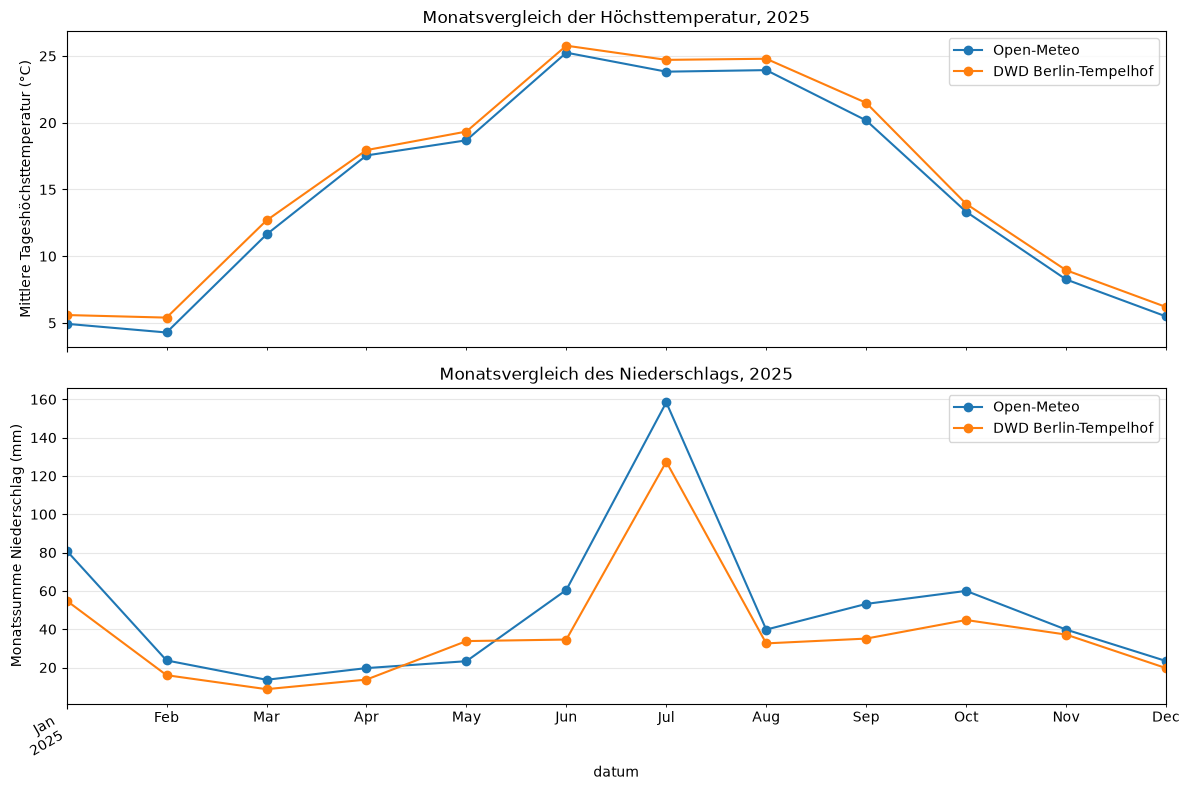

In [5]:
monat = vergleich.set_index("datum").resample("MS").agg({
    "temperatur_max_c_openmeteo": "mean",
    "temperatur_max_c_dwd": "mean",
    "niederschlag_mm_openmeteo": "sum",
    "niederschlag_mm_dwd": "sum",
})

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
monat["temperatur_max_c_openmeteo"].plot(
    ax=axes[0], marker="o", label="Open-Meteo"
)
monat["temperatur_max_c_dwd"].plot(
    ax=axes[0], marker="o", label="DWD Berlin-Tempelhof"
)
axes[0].set_ylabel("Mittlere Tageshöchsttemperatur (°C)")
axes[0].set_title("Monatsvergleich der Höchsttemperatur, 2025")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

monat["niederschlag_mm_openmeteo"].plot(
    ax=axes[1], marker="o", label="Open-Meteo"
)
monat["niederschlag_mm_dwd"].plot(
    ax=axes[1], marker="o", label="DWD Berlin-Tempelhof"
)
axes[1].set_ylabel("Monatssumme Niederschlag (mm)")
axes[1].set_title("Monatsvergleich des Niederschlags, 2025")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## 6. Größte Temperaturabweichungen finden

Diese Tabelle zeigt die Tage mit den größten Unterschieden bei der Tageshöchsttemperatur. So lassen sich einzelne Ausreißer zusätzlich zu den zusammengefassten Kennzahlen prüfen.

In [6]:
temperaturvergleich = vergleich.dropna(
    subset=["temperatur_max_c_openmeteo", "temperatur_max_c_dwd"]
).copy()
temperaturvergleich["abweichung_max_c"] = (
    temperaturvergleich["temperatur_max_c_openmeteo"]
    - temperaturvergleich["temperatur_max_c_dwd"]
)
temperaturvergleich["absolute_abweichung_c"] = temperaturvergleich["abweichung_max_c"].abs()

display(
    temperaturvergleich.nlargest(10, "absolute_abweichung_c")[
        ["datum", "temperatur_max_c_openmeteo", "temperatur_max_c_dwd", "abweichung_max_c"]
    ].reset_index(drop=True).round(2)
)

/tmp/ipykernel_22768/2832661694.py:13: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].reset_index(drop=True).round(2)


,datum,temperatur_max_c_openmeteo,temperatur_max_c_dwd,abweichung_max_c
0,2025-02-21,5.6,9.6,-4.0
1,2025-03-11,10.4,6.6,3.8
2,2025-07-03,29.5,25.8,3.7
3,2025-02-17,-2.5,1.0,-3.5
4,2025-07-14,24.9,27.8,-2.9
5,2025-03-05,14.9,17.8,-2.9
6,2025-07-11,21.8,24.6,-2.8
7,2025-07-27,23.9,26.6,-2.7
8,2025-08-24,18.4,21.0,-2.6
9,2025-09-25,14.5,17.1,-2.6
